# Processamento de imagens — questões 1 e 2


## Questão 1 (`question01.py`)


In [6]:
import cv2 as cv
import numpy as np

OUTPUT_DIR = 'answer01/'


### Função `TAM2`


A função `TAM2` amplia a imagem pelo fator indicado em `scale`, replicando os pixels da imagem original na imagem de saída. O resultado é salvo em `answer01/tam2.png`.


In [7]:
def TAM2(path: str, scale: int):

    img = cv.imread(path)
    assert img is not None, "file could not be read, check with os.path.exists()"

    H, W, _ = img.shape

    new_H = H * scale
    new_W = W * scale
    out = np.zeros((new_H, new_W, 3), dtype=img.dtype)

    for i in range(new_H):
        for j in range(new_W):
            source_x = j * W // new_W
            source_y = i * H // new_H

            out[i][j] = img[source_y][source_x]

    cv.imwrite(f'{OUTPUT_DIR}tam2.png', out)


### Função `TAMM`


A função `TAMM` dobra a largura e a altura da imagem. Primeiro posiciona os pixels originais e, em seguida, calcula médias entre pixels vizinhos para preencher as posições intermediárias. Salva imagens das etapas e o resultado final em `answer01/`.


In [8]:
def TAMM(path: str):

    img = cv.imread(path)
    assert img is not None, "file could not be read, check with os.path.exists()"

    H, W, _ = img.shape
    new_H = H * 2
    new_W = W * 2
    out = np.zeros((new_H, new_W, 3), dtype=img.dtype)

    for i in range(0,new_H, 2):
        for j in range(0,new_W,2):
            out[i][j] = img[i//2][j//2]
    cv.imwrite(f'{OUTPUT_DIR}tamm_step1.png', out)

    # linhas 
    for i in range(0,new_H,2):
        for j in range(1,new_W,2):
            if (j + 1) >= new_W:
                out[i][j] = img[i//2][j//2]
                continue
            prev = img[i//2][(j//2)]
            successor = img[i//2][(j//2) + 1]
            mean = (prev.astype(np.uint16) + successor.astype(np.uint16) + 1) // 2

            out[i][j] = mean.astype(np.uint8)   
    cv.imwrite(f'{OUTPUT_DIR}tamm_step2.png', out)

    # colunas
    for i in range(1,new_H,2):
        for j in range(0,new_W):
            if (i + 1) >= new_H:
                out[i][j] = out[i-1][j]
                continue
            prev = out[i-1][j]
            successor = out[i+1][j]
            mean = (prev.astype(np.uint16) + successor.astype(np.uint16) + 1) // 2

            out[i][j] = mean.astype(np.uint8)   
            
    cv.imwrite(f'{OUTPUT_DIR}tamm_step3.png', out)


### Função `SURPERRES`


A função `SURPERRES` combina duas imagens de mesma dimensão em uma imagem com o dobro da largura e da altura, usando cada imagem para preencher posições alternadas. O resultado é salvo em `answer01/superres.png`.


In [11]:
def SURPERRES(path1: str, path2: str):
    img1 = cv.imread(path1)
    assert img1 is not None, "img1 could not be read, check with os.path.exists()"
    img2 = cv.imread(path2)
    assert img2 is not None, "img2 could not be read, check with os.path.exists()"

    assert img1.shape == img2.shape, "images are not compatible"

    H, W, _ = img1.shape
    new_H = H*2
    new_W = W*2
    out = np.zeros((new_H, new_W, 3), dtype=img1.dtype)

    for i in range(new_H):
        for j in range(new_W):
            if i % 2 == 0 and j % 2 == 0:
                out[i][j] = img1[i//2][j//2]
            if i % 2 == 1 and j % 2 == 1:
                out[i][j] = img2[i//2][j//2]

    
    for i in range(new_H):
        k = i % 2
        for j in range(1-k, new_W, 2):
            value = np.zeros(3, dtype=np.int32)
            count = 0
            if (i > 0):
                value += out[i-1][j]
                count += 1
            if (i < new_H-1):
                value += out[i+1][j]
                count += 1
            if (j > 0):
                value += out[i][j-1]
                count += 1
            if (j < new_W-1):
                value += out[i][j+1]
                count += 1

            out[i][j] = value // count

    cv.imwrite(f"{OUTPUT_DIR}superres.png", out)


### Execução principal


In [12]:
from pathlib import Path

# Cada teste salva seus resultados em uma pasta própria para evitar sobrescrita.
output_dir_original = OUTPUT_DIR

# TAM2: ampliação de fruit01.
OUTPUT_DIR = "answer01/tam2_fruit01/"
Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)
TAM2("images/fruit01.png", 8)

# TAMM: testar uma imagem 4x4 e fruit01.
OUTPUT_DIR = "answer01/tamm_teste_4x4/"
Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)
TAMM("test_images/teste_4x4.png")

OUTPUT_DIR = "answer01/tamm_fruit01/"
Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)
TAMM("images/fruit01.png")

# SUPERRES: combinar cada um dos dois pares de imagens.
OUTPUT_DIR = "answer01/superres_fruits/"
Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)
SURPERRES("images/fruit01.png", "images/fruit02.png")

OUTPUT_DIR = "answer01/superres_teste_4x4/"
Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)
SURPERRES("test_images/teste_4x4.png", "test_images/teste_4x4_2.png")

# Restaurar o diretório padrão para as demais células do notebook.
OUTPUT_DIR = output_dir_original


## Questão 2 (`question02.py`)


In [5]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

OUT_DIR = Path("answer02")
IMAGENS = {
    "car.png": "images/car.png",
    "crowd.png": "images/crowd.png",
    "university.png": "images/university.png",
}

### 2.1 Realce power-law (correção gamma)

O código abaixo testa quatro valores de gamma para cada imagem: dois menores que 1 (`0.5` e `0.8`) e dois maiores que 1 (`1.2` e `1.5`). As comparações permitem observar o efeito de clarear ou escurecer cada imagem; a seleção do melhor resultado é visual.

In [7]:
GAMMAS = (0.5, 0.8, 1.2, 1.5)
MELHOR_GAMMA = {
    "car.png": 1.5,
    "crowd.png": 0.8,
    "university.png": 0.8,
}

In [3]:
def power_law(path: str, gamma: float, c: float = 1, output_path=None) -> np.ndarray:
    """Aplica correção gamma a uma imagem em tons de cinza e retorna o resultado."""
    img = cv.imread(path, flags=cv.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(f"Não foi possível ler a imagem: {path}")

    out = np.zeros(img.shape)
    cv.pow(img/255, gamma, out)
    out = np.clip(np.round(out * c * 255), 0, 255).astype(np.uint8)

    if output_path is not None:
        output_path = Path(output_path)
        output_path.parent.mkdir(parents=True, exist_ok=True)
        if not cv.imwrite(str(output_path), out):
            raise OSError(f"Não foi possível salvar a imagem: {output_path}")
        
    return out

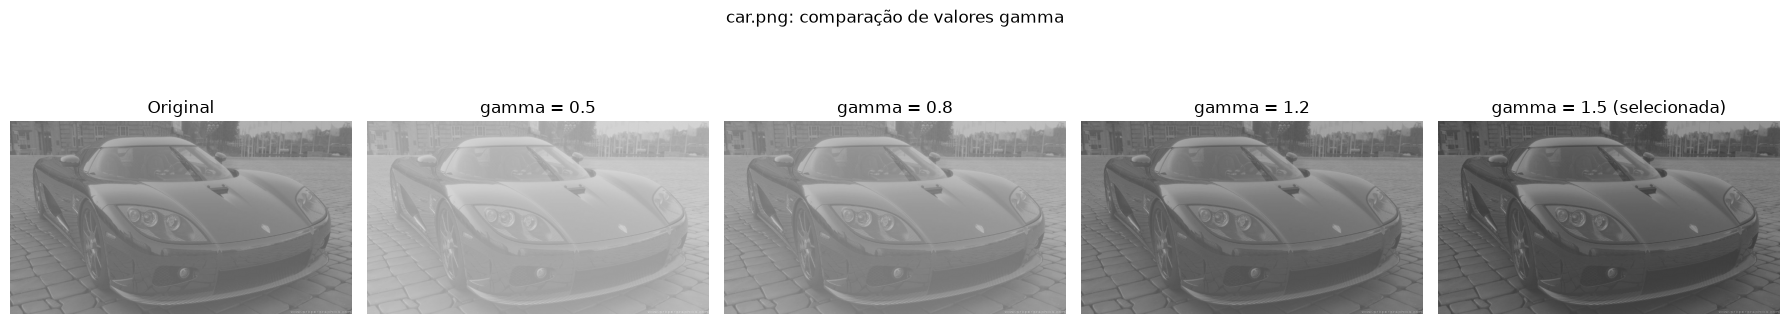

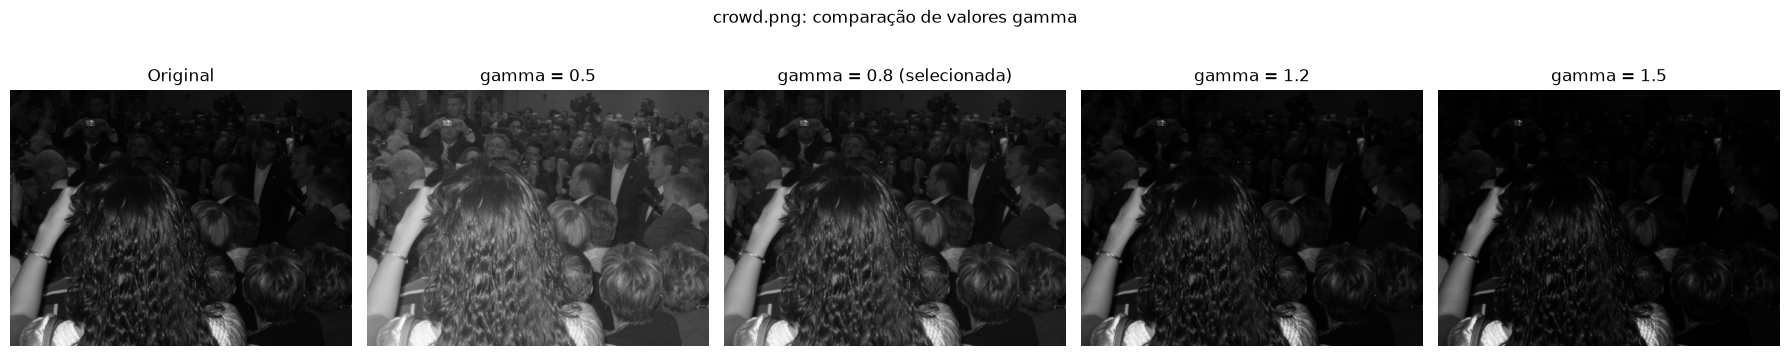

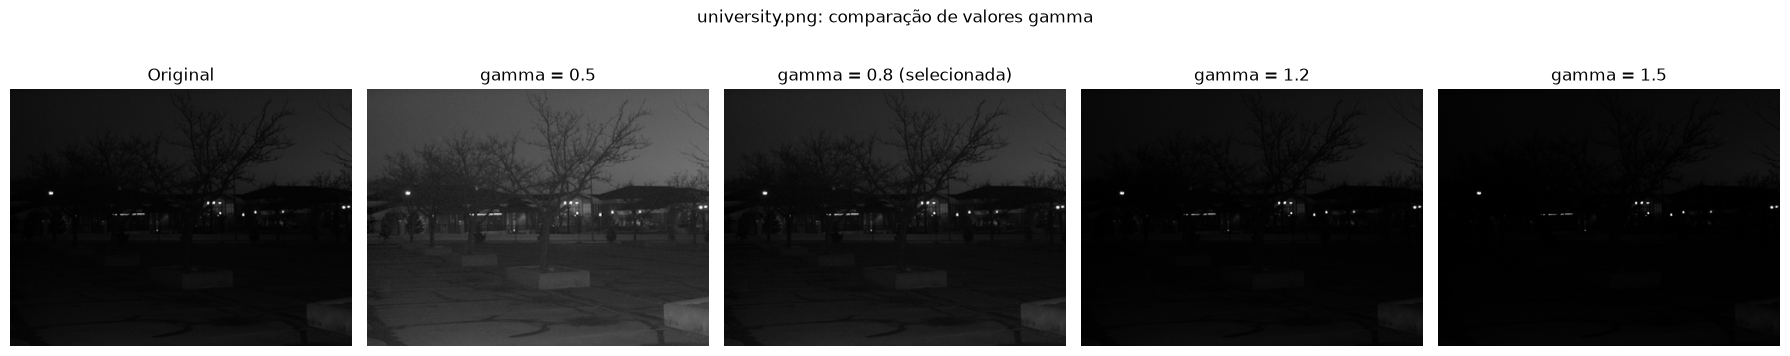

In [8]:
resultados_gamma = {}

for nome, caminho in IMAGENS.items():
    resultados_gamma[nome] = {}
    fig, eixos = plt.subplots(1, len(GAMMAS) + 1, figsize=(18, 4))

    original = cv.imread(caminho, flags=cv.IMREAD_GRAYSCALE)
    if original is None:
        raise FileNotFoundError(f"Não foi possível ler a imagem: {caminho}")
    eixos[0].imshow(original, cmap="gray", vmin=0, vmax=255)
    eixos[0].set_title("Original")
    eixos[0].axis("off")

    for eixo, gamma in zip(eixos[1:], GAMMAS):
        destino = OUT_DIR / "power_law" / "candidatas" / f"{Path(nome).stem}_gamma_{gamma:g}.png"
        resultado = power_law(caminho, gamma, output_path=destino)
        resultados_gamma[nome][gamma] = resultado
        eixo.imshow(resultado, cmap="gray", vmin=0, vmax=255)
        marcador = " (selecionada)" if gamma == MELHOR_GAMMA[nome] else ""
        eixo.set_title(f"gamma = {gamma:g}{marcador}")
        eixo.axis("off")

    fig.suptitle(f"{nome}: comparação de valores gamma")
    plt.tight_layout()
    plt.show()

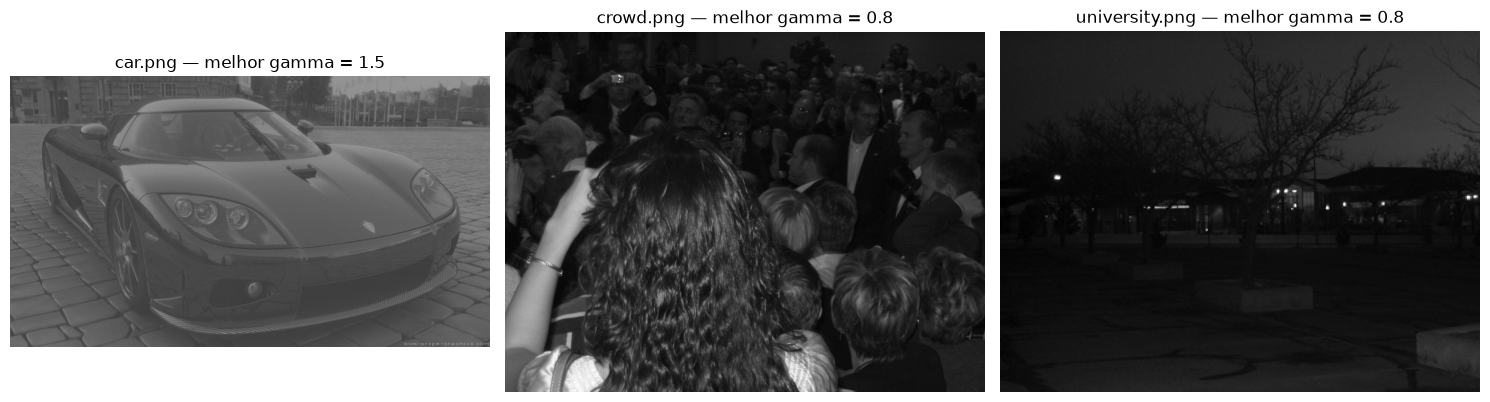

In [9]:
fig, eixos = plt.subplots(1, len(IMAGENS), figsize=(15, 5))

for eixo, (nome, _) in zip(eixos, IMAGENS.items()):
    gamma = MELHOR_GAMMA[nome]
    resultado = resultados_gamma[nome][gamma]
    destino = OUT_DIR / "power_law" / "melhores" / f"{Path(nome).stem}_gamma_{gamma:g}.png"
    destino.parent.mkdir(parents=True, exist_ok=True)
    if not cv.imwrite(str(destino), resultado):
        raise OSError(f"Não foi possível salvar a imagem: {destino}")
    eixo.imshow(resultado, cmap="gray", vmin=0, vmax=255)
    eixo.set_title(f"{nome} — melhor gamma = {gamma:g}")
    eixo.axis("off")

plt.tight_layout()
plt.show()

### 2.2 Equalização das três imagens

A equalização é aplicada às imagens `car.png`, `crowd.png` e `university.png`. Abaixo, cada original aparece ao lado de sua versão equalizada. Para a imagem `crowd.png`, também são exibidos e salvos o histograma e a CDF antes e depois da equalização.

In [10]:
def hist_cdf(im: np.ndarray):
    """Retorna histograma e CDF normalizada [0, 1] de uma imagem 8 bits de 1 canal."""
    hist = np.bincount(im.ravel(), minlength=256)
    cdf = hist.cumsum()
    return hist, cdf / cdf[-1]

In [11]:
def salvar_hist(hist: np.ndarray, titulo: str, caminho: str) -> None:
    plt.figure(figsize=(7, 4))
    plt.bar(range(256), hist, width=1)
    plt.title(titulo)
    plt.xlabel("Intensidade")
    plt.ylabel("Nº de pixels")
    plt.xlim(0, 255)
    plt.tight_layout()
    plt.savefig(caminho, dpi=150)
    plt.close()

In [12]:
def salvar_cdf(cdf: np.ndarray, titulo: str, caminho: str) -> None:
    plt.figure(figsize=(7, 4))
    plt.plot(cdf)
    plt.title(titulo)
    plt.xlabel("Intensidade")
    plt.ylabel("CDF")
    plt.xlim(0, 255)
    plt.ylim(0, 1.02)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(caminho, dpi=150)
    plt.close()

In [13]:
def equalizar(path: str, output_path=None) -> np.ndarray:
    """Equaliza uma imagem em tons de cinza, salva opcionalmente e retorna o resultado."""
    img = cv.imread(path, flags=cv.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(f"Não foi possível ler a imagem: {path}")

    eq = cv.equalizeHist(img)
    if output_path is not None:
        output_path = Path(output_path)
        output_path.parent.mkdir(parents=True, exist_ok=True)
        if not cv.imwrite(str(output_path), eq):
            raise OSError(f"Não foi possível salvar a imagem: {output_path}")
    return eq

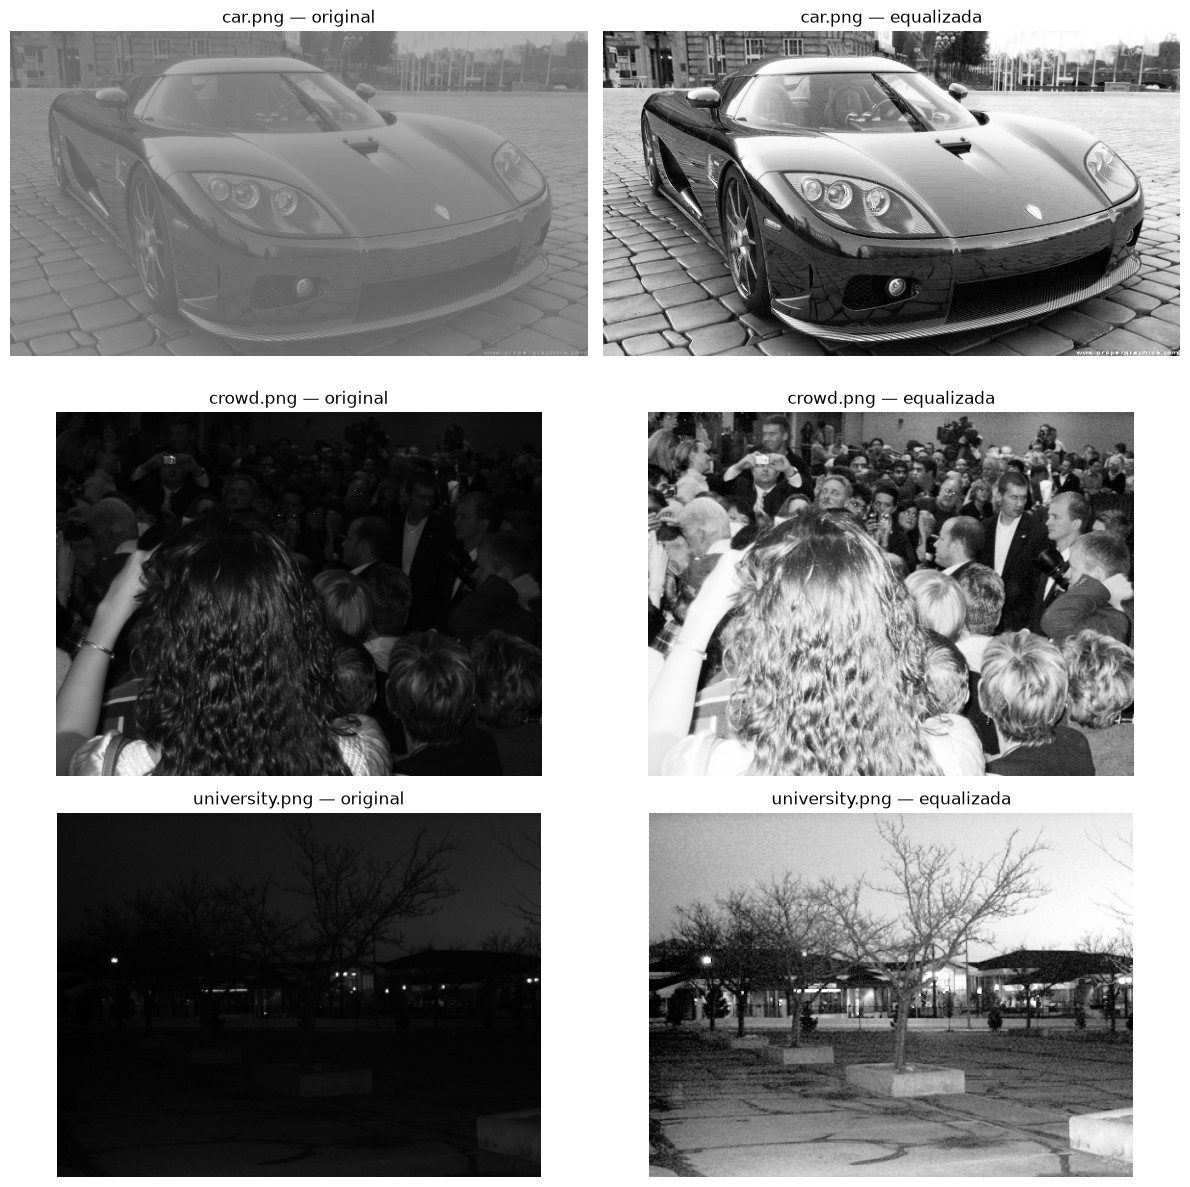

In [14]:
imagens_equalizadas = {}
fig, eixos = plt.subplots(len(IMAGENS), 2, figsize=(12, 12))

for linha, (nome, caminho) in enumerate(IMAGENS.items()):
    original = cv.imread(caminho, flags=cv.IMREAD_GRAYSCALE)
    if original is None:
        raise FileNotFoundError(f"Não foi possível ler a imagem: {caminho}")

    destino = OUT_DIR / "equalizadas" / f"{Path(nome).stem}_equalizada.png"
    equalizada = equalizar(caminho, output_path=destino)
    imagens_equalizadas[nome] = (original, equalizada)

    eixos[linha, 0].imshow(original, cmap="gray", vmin=0, vmax=255)
    eixos[linha, 0].set_title(f"{nome} — original")
    eixos[linha, 0].axis("off")
    eixos[linha, 1].imshow(equalizada, cmap="gray", vmin=0, vmax=255)
    eixos[linha, 1].set_title(f"{nome} — equalizada")
    eixos[linha, 1].axis("off")

plt.tight_layout()
plt.show()

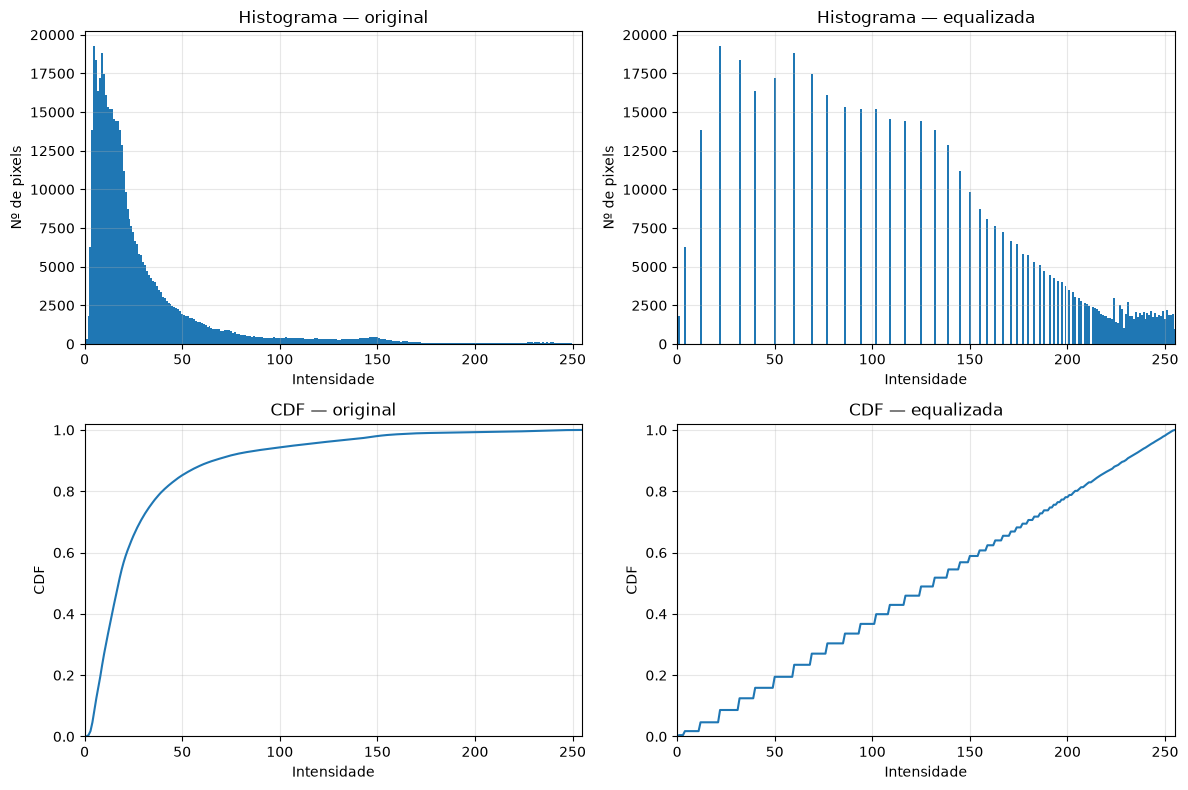

In [15]:
nome_histograma = "crowd.png"
original, equalizada = imagens_equalizadas[nome_histograma]
hist_original, cdf_original = hist_cdf(original)
hist_equalizado, cdf_equalizado = hist_cdf(equalizada)

fig, eixos = plt.subplots(2, 2, figsize=(12, 8))
eixos[0, 0].bar(range(256), hist_original, width=1)
eixos[0, 0].set_title("Histograma — original")
eixos[0, 0].set_xlabel("Intensidade")
eixos[0, 0].set_ylabel("Nº de pixels")
eixos[0, 1].bar(range(256), hist_equalizado, width=1)
eixos[0, 1].set_title("Histograma — equalizada")
eixos[0, 1].set_xlabel("Intensidade")
eixos[0, 1].set_ylabel("Nº de pixels")
eixos[1, 0].plot(cdf_original)
eixos[1, 0].set_title("CDF — original")
eixos[1, 0].set_xlabel("Intensidade")
eixos[1, 0].set_ylabel("CDF")
eixos[1, 0].set_ylim(0, 1.02)
eixos[1, 1].plot(cdf_equalizado)
eixos[1, 1].set_title("CDF — equalizada")
eixos[1, 1].set_xlabel("Intensidade")
eixos[1, 1].set_ylabel("CDF")
eixos[1, 1].set_ylim(0, 1.02)

for eixo in eixos.flat:
    eixo.set_xlim(0, 255)
    eixo.grid(alpha=0.3)

plt.tight_layout()
OUT_DIR.mkdir(parents=True, exist_ok=True)
plt.savefig(OUT_DIR / "crowd_histogramas_cdf.png", dpi=150)
plt.show()

salvar_hist(hist_original, "Histograma - original", str(OUT_DIR / "crowd_hist_original.png"))
salvar_cdf(cdf_original, "CDF - original", str(OUT_DIR / "crowd_cdf_original.png"))
salvar_hist(hist_equalizado, "Histograma - equalizada", str(OUT_DIR / "crowd_hist_equalizado.png"))
salvar_cdf(cdf_equalizado, "CDF - equalizada", str(OUT_DIR / "crowd_cdf_equalizada.png"))